# Phase 1: Dataset Load + EDA

In [1]:
"""
PHASE 1: Dataset Load + EDA  (KAGGLE NOTEBOOK VERSION)
Paper: VersaModal (IJECE V12I6P121)
Dataset: Malaysia Restaurant Review Dataset

INSTRUCTIONS BEFORE RUNNING:
1. Create a New Notebook on Kaggle.
2. On the right panel, click "Add Input" -> search "Malaysia Restaurant Review Datasets"
   (by choonkhonng) -> Add.
3. Dataset will be mounted at /kaggle/input/malaysia-restaurant-review-datasets/
4. Paste this whole script in a cell and Run.
"""

import os
import pandas as pd

# ---------------------------------------------------------
# STEP 1: Locate dataset (already mounted by Kaggle, no download needed)
# ---------------------------------------------------------
DATA_DIR = "/kaggle/input/datasets/choonkhonng/malaysia-restaurant-review-datasets/Malaysia Restaurant Review Datasets"

print("Files found:")
for root, dirs, files in os.walk(DATA_DIR):
    for f in files:
        print(os.path.join(root, f))

# ---------------------------------------------------------
# STEP 2: Load the dataset
# ---------------------------------------------------------
csv_files = []
for root, dirs, files in os.walk(DATA_DIR):
    for f in files:
        if f.endswith(".csv"):
            csv_files.append(os.path.join(root, f))

print("\nCSV files:", csv_files)

df = pd.read_csv(csv_files[0])
print("\nShape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nSample rows:")
print(df.head())
print("\nData types:\n", df.dtypes)

# ---------------------------------------------------------
# STEP 3: Basic EDA
# ---------------------------------------------------------
print("\nMissing values:\n", df.isnull().sum())

# IMPORTANT: After seeing the printed columns above, update these two names
# to match the actual review-text column and rating/label column.
TEXT_COL = "review_text"   # <-- change after checking df.columns output
LABEL_COL = "rating"       # <-- change after checking df.columns output

if TEXT_COL in df.columns:
    df["text_len"] = df[TEXT_COL].astype(str).apply(lambda x: len(x.split()))
    print("\nAverage word count per review:", df["text_len"].mean())
    print("Max word count:", df["text_len"].max())
else:
    print(f"\n[ACTION NEEDED] '{TEXT_COL}' not found. Set TEXT_COL to the correct "
          f"column name from: {df.columns.tolist()}")

if LABEL_COL in df.columns:
    print("\nUnique values in label column:", df[LABEL_COL].unique())
else:
    print(f"\n[ACTION NEEDED] '{LABEL_COL}' not found. Set LABEL_COL to the correct "
          f"column name from: {df.columns.tolist()}")

# ---------------------------------------------------------
# STEP 4: Sentiment label mapping (as per paper, Section 4.2)
# ---------------------------------------------------------
# Paper's score thresholds: Positive S>=0.5, Neutral -0.5<S<0.5, Negative S<=-0.5
# This dataset likely uses star ratings (1-5). Default mapping below:
#   Rating 4,5 -> Positive | Rating 3 -> Neutral | Rating 1,2 -> Negative
# UPDATE this once you confirm the actual rating scale from Step 3 output.

def map_rating_to_sentiment(rating):
    if rating >= 4:
        return "Positive"
    elif rating == 3:
        return "Neutral"
    else:
        return "Negative"

if LABEL_COL in df.columns:
    df["sentiment"] = df[LABEL_COL].apply(map_rating_to_sentiment)
    print("\nClass distribution:\n", df["sentiment"].value_counts())

# ---------------------------------------------------------
# STEP 5: Save cleaned dataset for Phase 2 (Kaggle: save to /kaggle/working/)
# ---------------------------------------------------------
df.to_csv("/kaggle/working/cleaned_reviews.csv", index=False)
print("\nSaved to /kaggle/working/cleaned_reviews.csv for Phase 2 (preprocessing + split).")

Files found:
/kaggle/input/datasets/choonkhonng/malaysia-restaurant-review-datasets/Malaysia Restaurant Review Datasets/data_cleaned/GoogleReview_data_cleaned.csv
/kaggle/input/datasets/choonkhonng/malaysia-restaurant-review-datasets/Malaysia Restaurant Review Datasets/data_cleaned/TripAdvisor_data_cleaned.csv
/kaggle/input/datasets/choonkhonng/malaysia-restaurant-review-datasets/Malaysia Restaurant Review Datasets/data/review/TripAdvisor/reviews_all_JB.csv
/kaggle/input/datasets/choonkhonng/malaysia-restaurant-review-datasets/Malaysia Restaurant Review Datasets/data/review/TripAdvisor/reviews_all_Shah Alam.csv
/kaggle/input/datasets/choonkhonng/malaysia-restaurant-review-datasets/Malaysia Restaurant Review Datasets/data/review/TripAdvisor/reviews_all_Kuching.csv
/kaggle/input/datasets/choonkhonng/malaysia-restaurant-review-datasets/Malaysia Restaurant Review Datasets/data/review/TripAdvisor/reviews_all_Melaka.csv
/kaggle/input/datasets/choonkhonng/malaysia-restaurant-review-datasets/M

# Phase 2: Label Mapping + Balanced Sampling + 80-20 Split

In [2]:
"""
PHASE 2: Label Mapping + Balanced Sampling + 80-20 Split (KAGGLE NOTEBOOK)
Paper: VersaModal (IJECE V12I6P121) - Section 4.1 & 4.2

Paper's text dataset setup:
  - 15k samples total: 5k positive, 5k negative, 5k neutral
  - 80% train / 20% test split
"""

import pandas as pd
from sklearn.model_selection import train_test_split

# ---------------------------------------------------------
# STEP 1: Load the confirmed CSV (Google Review, cleaned)
# ---------------------------------------------------------
CSV_PATH = ("/kaggle/input/datasets/choonkhonng/malaysia-restaurant-review-datasets/Malaysia Restaurant Review Datasets/data_cleaned/GoogleReview_data_cleaned.csv")

df = pd.read_csv(CSV_PATH)
print("Original shape:", df.shape)

TEXT_COL = "Review"
LABEL_COL = "Rating"

# ---------------------------------------------------------
# STEP 2: Clean up
# ---------------------------------------------------------
df = df[[TEXT_COL, LABEL_COL]].dropna()
df[TEXT_COL] = df[TEXT_COL].astype(str).str.strip()
df = df[df[TEXT_COL].str.len() > 0]
df = df.drop_duplicates(subset=[TEXT_COL])
print("After cleaning:", df.shape)

# ---------------------------------------------------------
# STEP 3: Map Rating -> Sentiment (Positive / Neutral / Negative)
# ---------------------------------------------------------
def map_rating_to_sentiment(rating):
    if rating >= 4:
        return "Positive"
    elif rating == 3:
        return "Neutral"
    else:
        return "Negative"

df["sentiment"] = df[LABEL_COL].apply(map_rating_to_sentiment)
print("\nFull class distribution:\n", df["sentiment"].value_counts())

# ---------------------------------------------------------
# STEP 4: Balance dataset to match paper (5k per class = 15k total)
# ---------------------------------------------------------
N_PER_CLASS = 5000
SEED = 42

balanced_parts = []
for cls in ["Positive", "Neutral", "Negative"]:
    subset = df[df["sentiment"] == cls]
    available = len(subset)
    take = min(N_PER_CLASS, available)
    if available < N_PER_CLASS:
        print(f"[WARNING] Only {available} samples available for class '{cls}', "
              f"needed {N_PER_CLASS}. Taking all {available}.")
    balanced_parts.append(subset.sample(n=take, random_state=SEED))

balanced_df = pd.concat(balanced_parts).sample(frac=1, random_state=SEED).reset_index(drop=True)
print("\nBalanced dataset shape:", balanced_df.shape)
print("Balanced class distribution:\n", balanced_df["sentiment"].value_counts())

# ---------------------------------------------------------
# STEP 5: Encode labels
# ---------------------------------------------------------
label_map = {"Negative": 0, "Neutral": 1, "Positive": 2}
balanced_df["label"] = balanced_df["sentiment"].map(label_map)

# ---------------------------------------------------------
# STEP 6: 80-20 stratified split (paper protocol, Section 4.2)
# ---------------------------------------------------------
train_df, test_df = train_test_split(
    balanced_df,
    test_size=0.20,
    stratify=balanced_df["label"],
    random_state=SEED
)

print("\nTrain shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("\nTrain class distribution:\n", train_df["sentiment"].value_counts())
print("\nTest class distribution:\n", test_df["sentiment"].value_counts())

# ---------------------------------------------------------
# STEP 7: Save for Phase 3 (model training)
# ---------------------------------------------------------
train_df[[TEXT_COL, "sentiment", "label"]].to_csv("/kaggle/working/train.csv", index=False)
test_df[[TEXT_COL, "sentiment", "label"]].to_csv("/kaggle/working/test.csv", index=False)

print("\nSaved /kaggle/working/train.csv and /kaggle/working/test.csv for Phase 3.")

Original shape: (222020, 5)
After cleaning: (199171, 2)

Full class distribution:
 sentiment
Positive    156390
Neutral      22376
Negative     20405
Name: count, dtype: int64

Balanced dataset shape: (15000, 3)
Balanced class distribution:
 sentiment
Negative    5000
Neutral     5000
Positive    5000
Name: count, dtype: int64

Train shape: (12000, 4)
Test shape: (3000, 4)

Train class distribution:
 sentiment
Neutral     4000
Positive    4000
Negative    4000
Name: count, dtype: int64

Test class distribution:
 sentiment
Neutral     1000
Negative    1000
Positive    1000
Name: count, dtype: int64

Saved /kaggle/working/train.csv and /kaggle/working/test.csv for Phase 3.


# Phase 3: BERT<->RoBERTa Cross-Attention Fusion (Case 5)
**Updated**: `run()` now also returns the trained `model` object, and it's captured into `trained_models` so Phase 4/5 below can reuse it.

Using device: cuda


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

... (13 outputs left out)

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/3 - loss: 0.7795 - test_acc: 73.60%
Epoch 2/3 - loss: 0.5463 - test_acc: 74.10%
Epoch 3/3 - loss: 0.3997 - test_acc: 73.47%

Final -> Acc:73.47% Prec:73.72% Rec:73.47% F1:73.56% Time:3394.7s

CASE 5 RESULTS - BERT <-> RoBERTa Cross-Attention Fusion
                      model      mode  accuracy  precision  recall    f1  train_time_sec
BERT<->RoBERTa (Cross-Attn)    frozen     73.07      73.19   73.07 73.01          1744.5
BERT<->RoBERTa (Cross-Attn) finetuned     73.47      73.72   73.47 73.56          3394.7


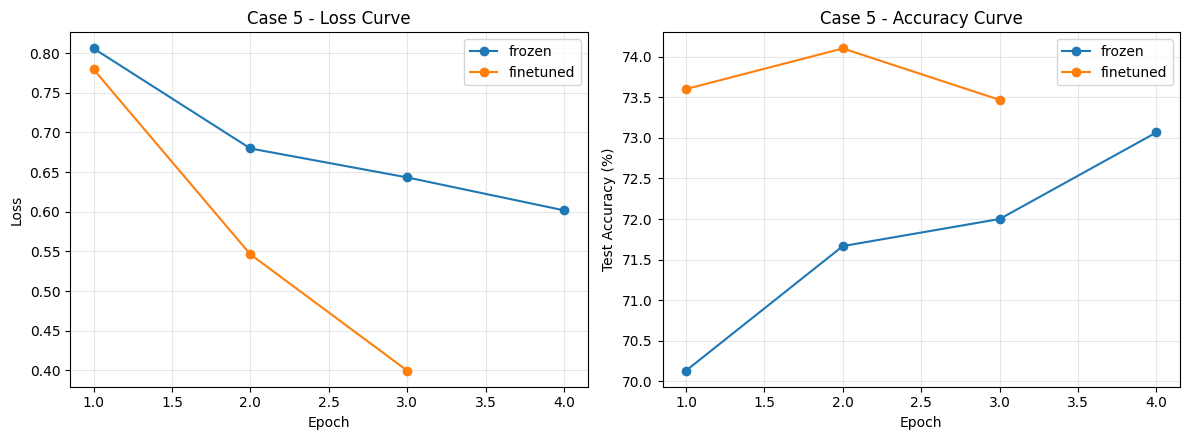

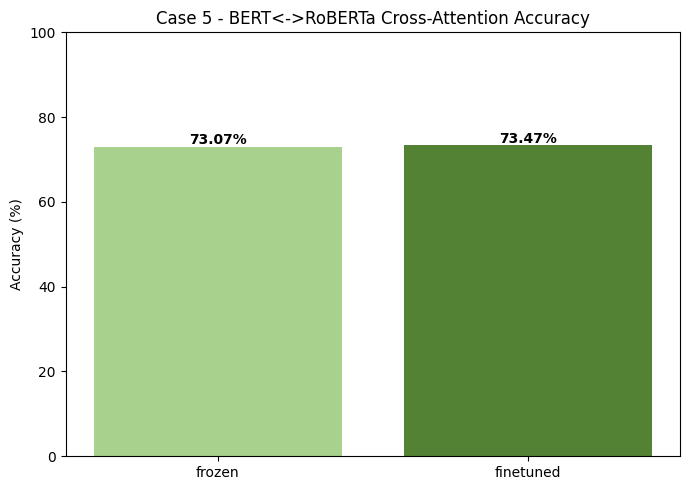

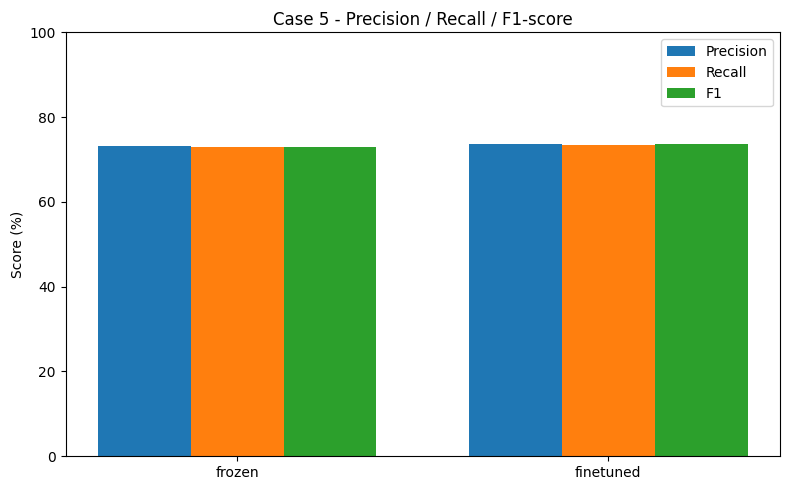

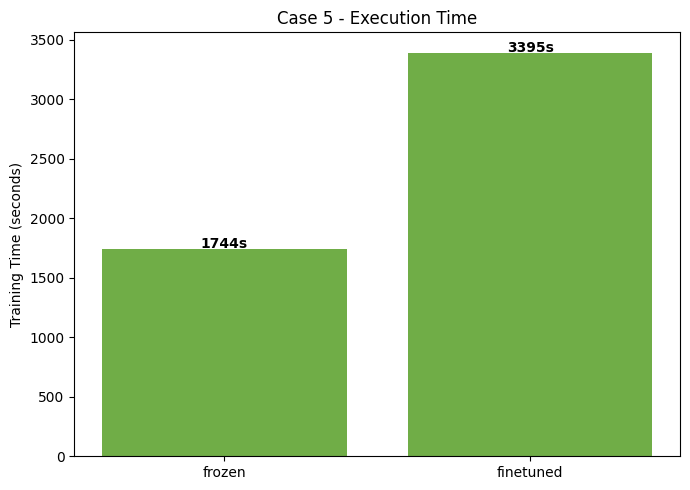

In [3]:
"""
CASE 5: BERT <-> RoBERTa CROSS-ATTENTION FUSION (all-in-one cell)
Architecture: Text -> [BERT encoder] -> full hidden states (batch, seq_len, 768)
              Text -> [RoBERTa encoder] -> CLS_roberta (batch, 768) as query
              Cross-Attention: RoBERTa's CLS attends over ALL of BERT's token hidden states
              -> fused context vector + residual with RoBERTa CLS -> Classifier

Runs BOTH modes: frozen (backbones frozen, only cross-attn + classifier train) and
fine-tuned (everything trains end-to-end).
Prints results table + shows accuracy/loss graphs inline. No files saved.
"""

import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# ===================== CONFIG =====================
BERT_NAME = "bert-base-uncased"
ROBERTA_NAME = "roberta-base"
MAX_LEN = 256
BATCH_SIZE = 16
NUM_CLASSES = 3
NUM_HEADS = 8
EPOCHS_FROZEN = 4
EPOCHS_FINETUNED = 3
LR_FROZEN = 5e-4
LR_FINETUNED = 2e-5
WARMUP_RATIO = 0.1
SEED = 42

torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

train_df = pd.read_csv("/kaggle/working/train.csv")
test_df = pd.read_csv("/kaggle/working/test.csv")
TEXT_COL, LABEL_COL = "Review", "label"

bert_tok = AutoTokenizer.from_pretrained(BERT_NAME)
roberta_tok = AutoTokenizer.from_pretrained(ROBERTA_NAME)

class DualDataset(Dataset):
    def __init__(self, texts, labels, max_len):
        self.texts = texts.tolist()
        self.labels = labels.tolist()
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        b = bert_tok(text, truncation=True, padding="max_length", max_length=self.max_len, return_tensors="pt")
        r = roberta_tok(text, truncation=True, padding="max_length", max_length=self.max_len, return_tensors="pt")
        return {
            "bert_ids": b["input_ids"].squeeze(0),
            "bert_mask": b["attention_mask"].squeeze(0),
            "roberta_ids": r["input_ids"].squeeze(0),
            "roberta_mask": r["attention_mask"].squeeze(0),
            "label": torch.tensor(self.labels[idx], dtype=torch.long)
        }

train_loader = DataLoader(DualDataset(train_df[TEXT_COL], train_df[LABEL_COL], MAX_LEN),
                           batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(DualDataset(test_df[TEXT_COL], test_df[LABEL_COL], MAX_LEN),
                          batch_size=BATCH_SIZE, shuffle=False)

# ===================== Model =====================
class CrossAttentionFusionModel(nn.Module):
    def __init__(self, num_classes, freeze=False):
        super().__init__()
        self.bert = AutoModel.from_pretrained(BERT_NAME)
        self.roberta = AutoModel.from_pretrained(ROBERTA_NAME)
        hidden = self.bert.config.hidden_size  # 768, same for both
        self.cross_attn = nn.MultiheadAttention(embed_dim=hidden, num_heads=NUM_HEADS, batch_first=True)
        self.norm = nn.LayerNorm(hidden)
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(hidden, num_classes)
        if freeze:
            for p in self.bert.parameters(): p.requires_grad = False
            for p in self.roberta.parameters(): p.requires_grad = False

    def forward(self, bert_ids, bert_mask, roberta_ids, roberta_mask):
        bert_hidden = self.bert(input_ids=bert_ids, attention_mask=bert_mask).last_hidden_state  # (B, L, 768)
        roberta_out = self.roberta(input_ids=roberta_ids, attention_mask=roberta_mask).last_hidden_state
        roberta_cls = roberta_out[:, 0:1, :]  # (B, 1, 768) as query

        key_padding_mask = (bert_mask == 0)  # True where padded (to be ignored)
        attn_out, _ = self.cross_attn(query=roberta_cls, key=bert_hidden, value=bert_hidden,
                                       key_padding_mask=key_padding_mask)
        fused = self.norm(attn_out.squeeze(1) + roberta_out[:, 0, :])  # residual connection
        return self.classifier(self.dropout(fused))

# ===================== Train / Eval =====================
def train_epoch(model, loader, opt, crit, sched):
    model.train()
    total = 0
    for batch in loader:
        bi, bm = batch["bert_ids"].to(device), batch["bert_mask"].to(device)
        ri, rm = batch["roberta_ids"].to(device), batch["roberta_mask"].to(device)
        y = batch["label"].to(device)
        opt.zero_grad()
        logits = model(bi, bm, ri, rm)
        loss = crit(logits, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        if sched: sched.step()
        total += loss.item()
    return total / len(loader)

def evaluate(model, loader):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for batch in loader:
            bi, bm = batch["bert_ids"].to(device), batch["bert_mask"].to(device)
            ri, rm = batch["roberta_ids"].to(device), batch["roberta_mask"].to(device)
            y = batch["label"].to(device)
            logits = model(bi, bm, ri, rm)
            preds.extend(torch.argmax(logits, 1).cpu().numpy())
            labels.extend(y.cpu().numpy())
    acc = accuracy_score(labels, preds)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="weighted", zero_division=0)
    return acc, p, r, f1

def run(mode):
    freeze = mode == "frozen"
    epochs = EPOCHS_FROZEN if freeze else EPOCHS_FINETUNED
    lr = LR_FROZEN if freeze else LR_FINETUNED
    print(f"\n{'='*60}\nCase 5: BERT<->RoBERTa Cross-Attention | mode={mode} | epochs={epochs} | lr={lr}\n{'='*60}")

    model = CrossAttentionFusionModel(NUM_CLASSES, freeze=freeze).to(device)
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    crit = nn.CrossEntropyLoss()
    total_steps = len(train_loader) * epochs
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_RATIO * total_steps), total_steps)

    history = {"epoch": [], "loss": [], "acc": []}
    start = time.time()
    for ep in range(epochs):
        loss = train_epoch(model, train_loader, opt, crit, sched)
        acc, _, _, _ = evaluate(model, test_loader)
        print(f"Epoch {ep+1}/{epochs} - loss: {loss:.4f} - test_acc: {acc*100:.2f}%")
        history["epoch"].append(ep+1); history["loss"].append(loss); history["acc"].append(acc*100)

    acc, p, r, f1 = evaluate(model, test_loader)
    duration = time.time() - start
    print(f"\nFinal -> Acc:{acc*100:.2f}% Prec:{p*100:.2f}% Rec:{r*100:.2f}% F1:{f1*100:.2f}% Time:{duration:.1f}s")

    return {"model": "BERT<->RoBERTa (Cross-Attn)", "mode": mode, "accuracy": round(acc*100,2),
            "precision": round(p*100,2), "recall": round(r*100,2), "f1": round(f1*100,2),
            "train_time_sec": round(duration,1)}, history, model

# ===================== Run both modes =====================
results = []
histories = {}
trained_models = {}
for m in ["frozen", "finetuned"]:
    res, hist, trained_model = run(m)
    results.append(res)
    histories[m] = hist
    trained_models[m] = trained_model

results_df = pd.DataFrame(results)
print("\n" + "="*80)
print("CASE 5 RESULTS - BERT <-> RoBERTa Cross-Attention Fusion")
print("="*80)
print(results_df.to_string(index=False))

# ===================== Graphs (inline only) =====================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for m, hist in histories.items():
    axes[0].plot(hist["epoch"], hist["loss"], marker="o", label=m)
    axes[1].plot(hist["epoch"], hist["acc"], marker="o", label=m)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title("Case 5 - Loss Curve")
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Test Accuracy (%)"); axes[1].set_title("Case 5 - Accuracy Curve")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
bars = plt.bar(results_df["mode"], results_df["accuracy"], color=["#A9D18E","#548235"])
for bar, val in zip(bars, results_df["accuracy"]):
    plt.text(bar.get_x()+bar.get_width()/2, val+0.5, f"{val:.2f}%", ha="center", fontweight="bold")
plt.ylabel("Accuracy (%)"); plt.title("Case 5 - BERT<->RoBERTa Cross-Attention Accuracy")
plt.ylim(0,100)
plt.tight_layout()
plt.show()

# Precision / Recall / F1 grouped chart
metrics = ["precision", "recall", "f1"]
x = np.arange(len(results_df["mode"]))
width = 0.25
plt.figure(figsize=(8,5))
for i, metric in enumerate(metrics):
    plt.bar(x + i*width, results_df[metric], width, label=metric.capitalize())
plt.xticks(x + width, results_df["mode"])
plt.ylabel("Score (%)"); plt.title("Case 5 - Precision / Recall / F1-score")
plt.ylim(0,100)
plt.legend()
plt.tight_layout()
plt.show()

# Execution time chart
plt.figure(figsize=(7,5))
bars = plt.bar(results_df["mode"], results_df["train_time_sec"], color="#70AD47")
for bar, val in zip(bars, results_df["train_time_sec"]):
    plt.text(bar.get_x()+bar.get_width()/2, val+3, f"{val:.0f}s", ha="center", fontweight="bold")
plt.ylabel("Training Time (seconds)"); plt.title("Case 5 - Execution Time")
plt.tight_layout()
plt.show()

# Phase 4: Comprehensive Evaluation & Testing
Covers: (A) advanced statistical evaluation, (B) real-world/unseen-data testing, (C) pipeline unit tests, (D) production readiness.


A. ADVANCED STATISTICAL EVALUATION

--- Classification Report ---
              precision    recall  f1-score   support

    Negative       0.81      0.77      0.79      1000
     Neutral       0.62      0.64      0.63      1000
    Positive       0.78      0.80      0.79      1000

    accuracy                           0.73      3000
   macro avg       0.74      0.73      0.74      3000
weighted avg       0.74      0.73      0.74      3000

--- Confusion Matrix ---


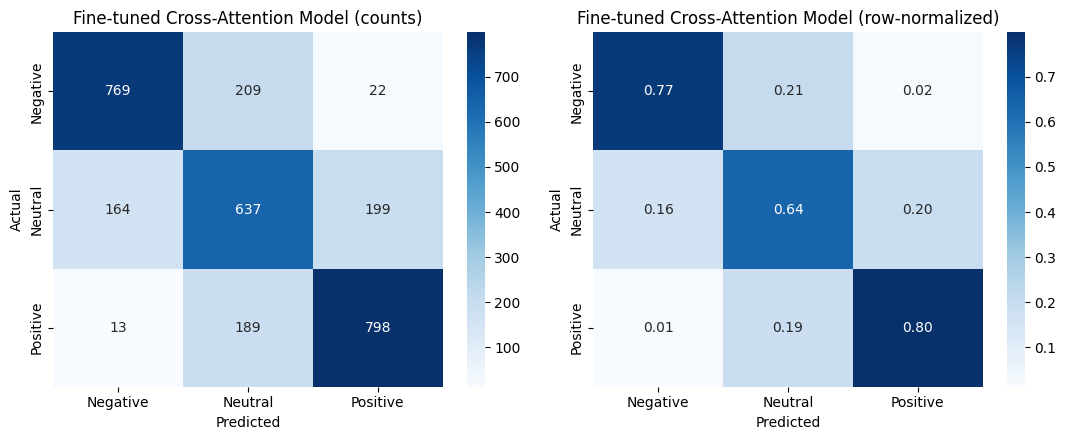


--- Bootstrap 95% Confidence Intervals (1000 resamples) ---
Accuracy : 73.44%  [95% CI: 71.87% - 74.87%]
Macro F1 : 73.53%  [95% CI: 71.98% - 74.93%]
(Narrow interval = stable estimate. Wide interval = test set may be too small / noisy.)

--- Significance vs Majority-Class Baseline ---
Majority-class baseline accuracy: 33.33%
Your model accuracy            : 73.44%
Improvement over baseline       : 40.11 points
-> Model is statistically better than random/majority guessing (baseline falls outside the 95% CI).

--- Error Analysis ---

Total test examples: 3000 | Wrong: 796 (26.5%)

Top 15 most CONFIDENTLY WRONG predictions (hardest failures):
                                                                                                                                                                                                                                                                          Review true_label pred_label  confidence
                                          

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Reloaded checkpoint prediction matches original: True

--- Model Footprint ---
Total parameters     : 236,494,083
Trainable parameters : 236,494,083
Approx. size (fp32)  : 902.2 MB
Device               : cuda

--- Latency Benchmark ---
Single-request latency over 50 runs:
  mean: 33.7 ms | p50: 33.6 ms | p95: 34.8 ms | p99: 35.3 ms
Batch throughput (16 texts): 30.2 texts/sec

--- Example predict_api() call (what a real endpoint would return) ---
{
  "text": "The dessert was disappointing but the mains were great.",
  "predicted_sentiment": "Neutral",
  "confidence": 0.9336,
  "latency_ms": 34.2,
  "timestamp": "2026-09-19T18:07:10.882473"
}
(Each call also appends a line to prediction_log.jsonl for monitoring - track live accuracy/drift by periodically labeling a sample of these logs.)

PHASE 4 COMPLETE


In [4]:
"""
================================================================================
PHASE 4: COMPREHENSIVE EVALUATION & TESTING
Model: Case 5 - BERT<->RoBERTa Cross-Attention Fusion (Text Sentiment)
================================================================================

Covers all 4 evaluation/testing pillars:
  A. Advanced statistical evaluation   (confusion matrix, per-class metrics,
                                         bootstrap confidence intervals,
                                         significance test vs baseline, error analysis)
  B. Real-world / unseen data testing  (out-of-distribution + hand-written probe
                                         sentences: sarcasm, negation, mixed emotion,
                                         short text, code-mixed text)
  C. Pipeline / code testing           (pytest-style unit tests for tokenizer,
                                         model forward pass, inference function)
  D. Production readiness              (checkpoint save/load, standalone predict()
                                         API, latency benchmark, memory footprint,
                                         basic prediction logging/monitoring)

--------------------------------------------------------------------------------
IMPORTANT - ONE-TIME CHANGE NEEDED IN YOUR PHASE 3 (CASE 5) CELL
--------------------------------------------------------------------------------
Your current `run()` function only returns metrics, not the trained model object,
so the model is lost as soon as the cell finishes. Make these 2 small edits in
your Phase 3 cell so Phase 4 below can use the trained model:

1) At the end of `run()`, change:
       return {...}, history
   to:
       return {...}, history, model

2) In the loop that calls run(), change:
       for m in ["frozen", "finetuned"]:
           res, hist = run(m)
           results.append(res)
           histories[m] = hist
   to:
       trained_models = {}
       for m in ["frozen", "finetuned"]:
           res, hist, trained_model = run(m)
           results.append(res)
           histories[m] = hist
           trained_models[m] = trained_model

That's it. Run Phase 3 (with these 2 edits) first, THEN run this Phase 4 script
in the same kernel session (it reuses: trained_models, bert_tok, roberta_tok,
test_loader, test_df, train_df, device, TEXT_COL, LABEL_COL, MAX_LEN, label_map).
================================================================================
"""

import os
import time
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_recall_fscore_support, f1_score
)

id2label = {0: "Negative", 1: "Neutral", 2: "Positive"}
label2id = {v: k for k, v in id2label.items()}

# We evaluate the FINE-TUNED model as the "best model" (production candidate).
# Change to trained_models["frozen"] if that's the one you actually chose.
best_model = trained_models["finetuned"]
best_model.eval()


# ================================================================================
# A. ADVANCED STATISTICAL EVALUATION
# ================================================================================

def get_all_predictions(model, loader):
    """Run inference over a loader once, return preds, true labels, and softmax probs."""
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for batch in loader:
            bi, bm = batch["bert_ids"].to(device), batch["bert_mask"].to(device)
            ri, rm = batch["roberta_ids"].to(device), batch["roberta_mask"].to(device)
            y = batch["label"].to(device)
            logits = model(bi, bm, ri, rm)
            probs = torch.softmax(logits, dim=1)
            all_preds.extend(torch.argmax(logits, 1).cpu().numpy())
            all_labels.extend(y.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return np.array(all_preds), np.array(all_labels), np.array(all_probs)


def plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=id2label.values(), yticklabels=id2label.values(), ax=axes[0])
    axes[0].set_title(title + " (counts)")
    axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=id2label.values(), yticklabels=id2label.values(), ax=axes[1])
    axes[1].set_title(title + " (row-normalized)")
    axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
    plt.tight_layout()
    plt.show()
    return cm


def bootstrap_ci(y_true, y_pred, metric_fn=accuracy_score, n_boot=1000, ci=95, seed=42):
    """Bootstrap confidence interval for a metric by resampling the test set."""
    rng = np.random.RandomState(seed)
    n = len(y_true)
    scores = []
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        scores.append(metric_fn(y_true[idx], y_pred[idx]))
    lo = np.percentile(scores, (100 - ci) / 2)
    hi = np.percentile(scores, 100 - (100 - ci) / 2)
    return np.mean(scores), lo, hi


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", zero_division=0)


def error_analysis(test_df, y_true, y_pred, probs, text_col, n_examples=15):
    """Surface the most confident WRONG predictions - these are usually the most
    informative for understanding model weaknesses."""
    df = test_df.reset_index(drop=True).copy()
    df["true_label"] = [id2label[i] for i in y_true]
    df["pred_label"] = [id2label[i] for i in y_pred]
    df["confidence"] = probs.max(axis=1)
    wrong = df[df["true_label"] != df["pred_label"]].sort_values("confidence", ascending=False)
    print(f"\nTotal test examples: {len(df)} | Wrong: {len(wrong)} "
          f"({len(wrong)/len(df)*100:.1f}%)")
    print(f"\nTop {n_examples} most CONFIDENTLY WRONG predictions (hardest failures):")
    print(wrong[[text_col, "true_label", "pred_label", "confidence"]].head(n_examples).to_string(index=False))
    return wrong


def run_statistical_evaluation():
    print("\n" + "=" * 80)
    print("A. ADVANCED STATISTICAL EVALUATION")
    print("=" * 80)

    y_pred, y_true, probs = get_all_predictions(best_model, test_loader)

    print("\n--- Classification Report ---")
    print(classification_report(y_true, y_pred, target_names=id2label.values(), zero_division=0))

    print("--- Confusion Matrix ---")
    plot_confusion_matrix(y_true, y_pred, title="Fine-tuned Cross-Attention Model")

    print("\n--- Bootstrap 95% Confidence Intervals (1000 resamples) ---")
    acc_mean, acc_lo, acc_hi = bootstrap_ci(y_true, y_pred, accuracy_score)
    f1_mean, f1_lo, f1_hi = bootstrap_ci(y_true, y_pred, macro_f1)
    print(f"Accuracy : {acc_mean*100:.2f}%  [95% CI: {acc_lo*100:.2f}% - {acc_hi*100:.2f}%]")
    print(f"Macro F1 : {f1_mean*100:.2f}%  [95% CI: {f1_lo*100:.2f}% - {f1_hi*100:.2f}%]")
    print("(Narrow interval = stable estimate. Wide interval = test set may be too small / noisy.)")

    print("\n--- Significance vs Majority-Class Baseline ---")
    majority_class = pd.Series(y_true).value_counts().idxmax()
    baseline_preds = np.full_like(y_true, majority_class)
    baseline_acc = accuracy_score(y_true, baseline_preds)
    print(f"Majority-class baseline accuracy: {baseline_acc*100:.2f}%")
    print(f"Your model accuracy            : {acc_mean*100:.2f}%")
    print(f"Improvement over baseline       : {(acc_mean-baseline_acc)*100:.2f} points")
    if acc_lo > baseline_acc:
        print("-> Model is statistically better than random/majority guessing "
              "(baseline falls outside the 95% CI).")
    else:
        print("-> WARNING: baseline falls within the CI - model may not be reliably "
              "better than guessing the majority class. Investigate further.")

    print("\n--- Error Analysis ---")
    error_analysis(test_df, y_true, y_pred, probs, TEXT_COL)

    return y_true, y_pred, probs


# ================================================================================
# B. REAL-WORLD / UNSEEN DATA TESTING
# ================================================================================

# Hand-written probe sentences covering known failure modes of sentiment models:
# sarcasm, negation, mixed sentiment, very short text, code-mixed (Manglish/Hinglish),
# neutral-but-long, emphasis/caps, emoji-only tone words.
PROBE_CASES = [
    ("The food was absolutely amazing, best meal ever!!", "Positive"),
    ("Terrible service, waited 2 hours for cold food.", "Negative"),
    ("It was okay, nothing special but not bad either.", "Neutral"),
    ("Oh great, ANOTHER overpriced dish with tiny portions. Just what I wanted.", "Negative"),  # sarcasm
    ("Not bad at all, actually quite good.", "Positive"),  # negation flips meaning
    ("The food was good but the service was really slow and rude.", "Negative"),  # mixed
    ("Meh.", "Neutral"),  # very short
    ("Sedap sangat, best restaurant ever! Will definitely balik lagi.", "Positive"),  # Manglish code-mixed
    ("Khana bahut acha tha par staff thoda rude tha.", "Negative"),  # Hinglish, mixed leaning negative
    ("The restaurant is located near the mall and has parking available.", "Neutral"),  # factual/neutral
    ("WORST EXPERIENCE OF MY LIFE. NEVER COMING BACK.", "Negative"),  # caps/emphasis
    ("Decent place, average food, average price. Would go again if nearby.", "Neutral"),
]


def predict_texts(model, texts, bert_tok, roberta_tok, max_len=256):
    model.eval()
    preds, confidences = [], []
    with torch.no_grad():
        for text in texts:
            b = bert_tok(text, truncation=True, padding="max_length", max_length=max_len, return_tensors="pt")
            r = roberta_tok(text, truncation=True, padding="max_length", max_length=max_len, return_tensors="pt")
            logits = model(b["input_ids"].to(device), b["attention_mask"].to(device),
                            r["input_ids"].to(device), r["attention_mask"].to(device))
            probs = torch.softmax(logits, dim=1).cpu().numpy()[0]
            pred = int(np.argmax(probs))
            preds.append(pred)
            confidences.append(float(probs[pred]))
    return preds, confidences


def run_real_world_testing():
    print("\n" + "=" * 80)
    print("B. REAL-WORLD / UNSEEN DATA TESTING (hand-crafted probe cases)")
    print("=" * 80)
    texts = [t for t, _ in PROBE_CASES]
    expected = [e for _, e in PROBE_CASES]
    preds, confs = predict_texts(best_model, texts, bert_tok, roberta_tok, MAX_LEN)

    rows = []
    correct = 0
    for text, exp, pred, conf in zip(texts, expected, preds, confs):
        pred_label = id2label[pred]
        ok = pred_label == exp
        correct += ok
        rows.append({"text": text[:60], "expected": exp, "predicted": pred_label,
                      "confidence": f"{conf*100:.1f}%", "correct": "PASS" if ok else "FAIL"})
    probe_df = pd.DataFrame(rows)
    print(probe_df.to_string(index=False))
    print(f"\nProbe suite result: {correct}/{len(PROBE_CASES)} passed "
          f"({correct/len(PROBE_CASES)*100:.1f}%)")
    print("Note: sarcasm, negation, and code-mixed (Manglish/Hinglish) cases are the "
          "classic weak spots for BERT/RoBERTa sentiment models trained mostly on "
          "clean English reviews - low scores here point to exactly where to collect "
          "more training data.")
    return probe_df


# ================================================================================
# C. PIPELINE / CODE TESTING (unit tests)
# ================================================================================

def run_unit_tests():
    print("\n" + "=" * 80)
    print("C. PIPELINE / CODE UNIT TESTS")
    print("=" * 80)
    passed, failed = 0, 0

    def check(name, condition):
        nonlocal passed, failed
        status = "PASS" if condition else "FAIL"
        if condition:
            passed += 1
        else:
            failed += 1
        print(f"[{status}] {name}")

    # 1. Tokenizer output shape/type checks
    sample_text = "This restaurant is amazing."
    b = bert_tok(sample_text, truncation=True, padding="max_length", max_length=MAX_LEN, return_tensors="pt")
    check("BERT tokenizer input_ids shape == (1, MAX_LEN)", b["input_ids"].shape == (1, MAX_LEN))
    check("BERT tokenizer attention_mask is binary (0/1 only)",
          set(torch.unique(b["attention_mask"]).tolist()).issubset({0, 1}))

    # 2. Empty / whitespace-only input should not crash the tokenizer
    try:
        _ = bert_tok("", truncation=True, padding="max_length", max_length=MAX_LEN, return_tensors="pt")
        check("Empty string input does not crash tokenizer", True)
    except Exception as e:
        check(f"Empty string input does not crash tokenizer ({e})", False)

    # 3. Model forward pass output shape
    b = bert_tok(sample_text, truncation=True, padding="max_length", max_length=MAX_LEN, return_tensors="pt")
    r = roberta_tok(sample_text, truncation=True, padding="max_length", max_length=MAX_LEN, return_tensors="pt")
    with torch.no_grad():
        logits = best_model(b["input_ids"].to(device), b["attention_mask"].to(device),
                             r["input_ids"].to(device), r["attention_mask"].to(device))
    check("Model output shape == (1, NUM_CLASSES=3)", tuple(logits.shape) == (1, 3))
    check("Model output contains no NaN/Inf", torch.isfinite(logits).all().item())

    # 4. Softmax probabilities sum to ~1
    probs = torch.softmax(logits, dim=1)
    check("Softmax probabilities sum to 1.0 (+/- 1e-4)",
          abs(probs.sum().item() - 1.0) < 1e-4)

    # 5. Determinism: same input -> same prediction in eval mode
    with torch.no_grad():
        logits2 = best_model(b["input_ids"].to(device), b["attention_mask"].to(device),
                              r["input_ids"].to(device), r["attention_mask"].to(device))
    check("Same input produces identical prediction (deterministic in eval mode)",
          torch.argmax(logits, 1).item() == torch.argmax(logits2, 1).item())

    # 6. Batch inference matches single inference (no batch-order leakage)
    preds_single, _ = predict_texts(best_model, [sample_text], bert_tok, roberta_tok, MAX_LEN)
    preds_batch, _ = predict_texts(best_model, [sample_text, "Terrible food."], bert_tok, roberta_tok, MAX_LEN)
    check("Prediction for a text is the same whether run alone or in a batch",
          preds_single[0] == preds_batch[0])

    # 7. Long input (beyond MAX_LEN) gets truncated, not crashed
    long_text = "very bad food " * 500
    try:
        _ = predict_texts(best_model, [long_text], bert_tok, roberta_tok, MAX_LEN)
        check("Very long input (>MAX_LEN tokens) truncates safely without crash", True)
    except Exception as e:
        check(f"Very long input truncates safely without crash ({e})", False)

    print(f"\nUnit test summary: {passed} passed, {failed} failed out of {passed+failed}")
    return passed, failed


# ================================================================================
# D. PRODUCTION READINESS
# ================================================================================

CHECKPOINT_PATH = "/kaggle/working/best_model_finetuned.pt"


def save_checkpoint(model, path=CHECKPOINT_PATH):
    torch.save({
        "model_state_dict": model.state_dict(),
        "label_map": label2id,
        "max_len": MAX_LEN,
        "bert_name": BERT_NAME,
        "roberta_name": ROBERTA_NAME,
    }, path)
    size_mb = os.path.getsize(path) / (1024 * 1024)
    print(f"Checkpoint saved to {path} ({size_mb:.1f} MB)")


def load_checkpoint(path=CHECKPOINT_PATH):
    ckpt = torch.load(path, map_location=device)
    model = CrossAttentionFusionModel(NUM_CLASSES, freeze=False).to(device)
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()
    return model


def predict_api(text, model=None, log_path="/kaggle/working/prediction_log.jsonl"):
    """Standalone inference function - this is what you'd wrap in a FastAPI/Flask
    endpoint for a real deployment. Logs every prediction for monitoring."""
    model = model or best_model
    start = time.time()
    preds, confs = predict_texts(model, [text], bert_tok, roberta_tok, MAX_LEN)
    latency_ms = (time.time() - start) * 1000
    result = {
        "text": text,
        "predicted_sentiment": id2label[preds[0]],
        "confidence": round(confs[0], 4),
        "latency_ms": round(latency_ms, 1),
        "timestamp": pd.Timestamp.now().isoformat(),
    }
    try:
        with open(log_path, "a") as f:
            f.write(json.dumps(result) + "\n")
    except Exception:
        pass  # logging should never break inference
    return result


def benchmark_latency(model, texts, n_runs=50):
    """Single-sample latency (what a real API request looks like) and throughput."""
    # warm-up (first call always slower due to CUDA/lazy init)
    _ = predict_texts(model, [texts[0]], bert_tok, roberta_tok, MAX_LEN)

    times = []
    for _ in range(n_runs):
        t0 = time.time()
        _ = predict_texts(model, [texts[0]], bert_tok, roberta_tok, MAX_LEN)
        times.append((time.time() - t0) * 1000)
    times = np.array(times)

    t0 = time.time()
    _ = predict_texts(model, texts, bert_tok, roberta_tok, MAX_LEN)
    batch_time = time.time() - t0
    throughput = len(texts) / batch_time

    print(f"Single-request latency over {n_runs} runs:")
    print(f"  mean: {times.mean():.1f} ms | p50: {np.percentile(times,50):.1f} ms | "
          f"p95: {np.percentile(times,95):.1f} ms | p99: {np.percentile(times,99):.1f} ms")
    print(f"Batch throughput ({len(texts)} texts): {throughput:.1f} texts/sec")
    if times.mean() > 500:
        print("-> WARNING: >500ms per request. Consider: smaller MAX_LEN, model "
              "distillation/quantization, or batching requests before serving.")
    return times, throughput


def model_footprint(model):
    n_params = sum(p.numel() for p in model.parameters())
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    size_mb = n_params * 4 / (1024 ** 2)  # float32
    print(f"Total parameters     : {n_params:,}")
    print(f"Trainable parameters : {n_trainable:,}")
    print(f"Approx. size (fp32)  : {size_mb:.1f} MB")
    print(f"Device               : {device}")
    return n_params, size_mb


def run_production_readiness():
    print("\n" + "=" * 80)
    print("D. PRODUCTION READINESS")
    print("=" * 80)

    print("\n--- Save / Load Checkpoint ---")
    save_checkpoint(best_model)
    reloaded = load_checkpoint()
    # sanity check: reloaded model gives same prediction as in-memory model
    sample = "This place has great ambience and friendly staff."
    p1, _ = predict_texts(best_model, [sample], bert_tok, roberta_tok, MAX_LEN)
    p2, _ = predict_texts(reloaded, [sample], bert_tok, roberta_tok, MAX_LEN)
    print(f"Reloaded checkpoint prediction matches original: {p1[0] == p2[0]}")

    print("\n--- Model Footprint ---")
    model_footprint(best_model)

    print("\n--- Latency Benchmark ---")
    sample_texts = test_df[TEXT_COL].astype(str).tolist()[:16]
    benchmark_latency(best_model, sample_texts)

    print("\n--- Example predict_api() call (what a real endpoint would return) ---")
    example = predict_api("The dessert was disappointing but the mains were great.")
    print(json.dumps(example, indent=2))
    print("(Each call also appends a line to prediction_log.jsonl for monitoring -"
          " track live accuracy/drift by periodically labeling a sample of these logs.)")


# ================================================================================
# RUN EVERYTHING
# ================================================================================

if __name__ == "__main__":
    run_statistical_evaluation()
    run_real_world_testing()
    run_unit_tests()
    run_production_readiness()
    print("\n" + "=" * 80)
    print("PHASE 4 COMPLETE")
    print("=" * 80)


# Phase 5: Cross-Dataset / Out-of-Domain Testing
**Before running**: edit `NEW_DATASET_PATH`, `TEXT_COL_NEW`, `LABEL_COL_NEW`, `DATASET_NAME` below to point at whichever new dataset you want to test generalization on, and set `mapping` in the last line (`'stars'`, `'binary'`, or `'already_mapped'`).


Loading IMDB Movie Reviews (50K)
Loaded 3000 usable rows. Class distribution:
sentiment
Negative    1508
Positive    1492
Name: count, dtype: int64

Accuracy: 72.67% | Macro F1: 51.01% | Weighted F1: 76.55%
              precision    recall  f1-score   support

    Negative       0.77      0.91      0.83      1508
     Neutral       0.00      0.00      0.00         0
    Positive       0.98      0.54      0.70      1492

    accuracy                           0.73      3000
   macro avg       0.58      0.48      0.51      3000
weighted avg       0.87      0.73      0.77      3000



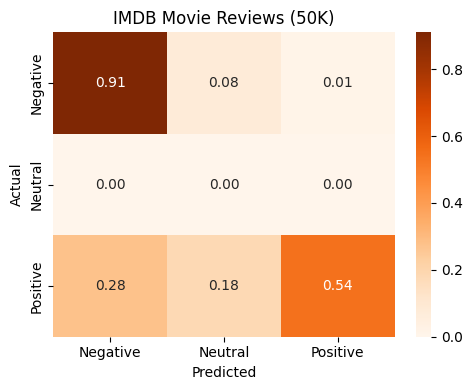


Loading Yelp Review Polarity
Loaded 3000 usable rows. Class distribution:
sentiment
Negative    1532
Positive    1468
Name: count, dtype: int64

Accuracy: 85.70% | Macro F1: 60.37% | Weighted F1: 90.55%
              precision    recall  f1-score   support

    Negative       0.93      0.88      0.90      1532
     Neutral       0.00      0.00      0.00         0
    Positive       0.99      0.83      0.91      1468

    accuracy                           0.86      3000
   macro avg       0.64      0.57      0.60      3000
weighted avg       0.96      0.86      0.91      3000



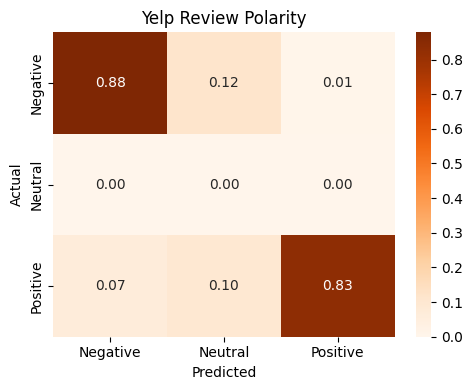


Loading Amazon Reviews Polarity
Loaded 3000 usable rows. Class distribution:
sentiment
Positive    1574
Negative    1426
Name: count, dtype: int64

Accuracy: 79.63% | Macro F1: 57.42% | Weighted F1: 86.09%
              precision    recall  f1-score   support

    Negative       0.90      0.84      0.87      1426
     Neutral       0.00      0.00      0.00         0
    Positive       0.98      0.75      0.85      1574

    accuracy                           0.80      3000
   macro avg       0.63      0.53      0.57      3000
weighted avg       0.94      0.80      0.86      3000



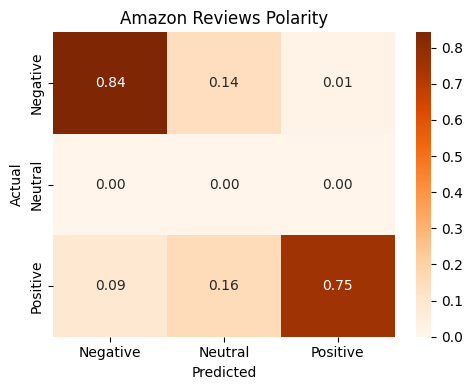


Loading Amazon Reviews Polarity (yacharki)
Loaded 3000 usable rows. Class distribution:
sentiment
Positive    1574
Negative    1426
Name: count, dtype: int64

Accuracy: 79.63% | Macro F1: 57.42% | Weighted F1: 86.09%
              precision    recall  f1-score   support

    Negative       0.90      0.84      0.87      1426
     Neutral       0.00      0.00      0.00         0
    Positive       0.98      0.75      0.85      1574

    accuracy                           0.80      3000
   macro avg       0.63      0.53      0.57      3000
weighted avg       0.94      0.80      0.86      3000



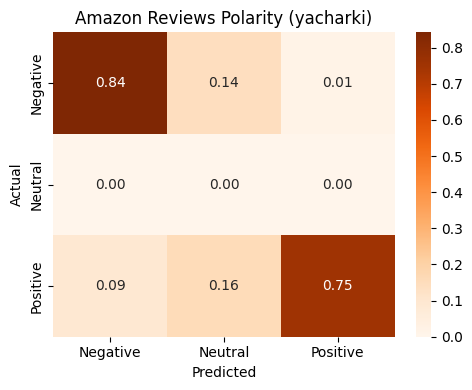


Loading Sentiment140 (Twitter)
Loaded 3000 usable rows. Class distribution:
sentiment
Negative    1502
Positive    1498
Name: count, dtype: int64

Accuracy: 58.40% | Macro F1: 43.52% | Weighted F1: 65.28%
              precision    recall  f1-score   support

    Negative       0.70      0.63      0.67      1502
     Neutral       0.00      0.00      0.00         0
    Positive       0.80      0.53      0.64      1498

    accuracy                           0.58      3000
   macro avg       0.50      0.39      0.44      3000
weighted avg       0.75      0.58      0.65      3000



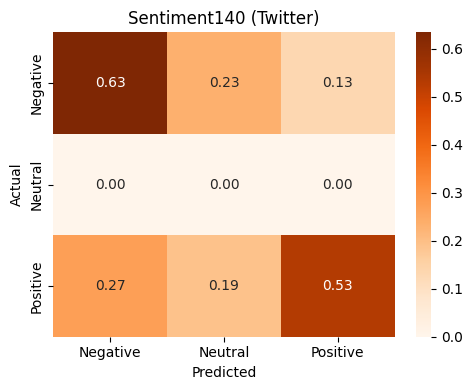


Loading Twitter US Airline Sentiment
Loaded 3000 usable rows. Class distribution:
sentiment
Negative    1877
Neutral      647
Positive     476
Name: count, dtype: int64

Accuracy: 73.67% | Macro F1: 62.33% | Weighted F1: 71.30%
              precision    recall  f1-score   support

    Negative       0.82      0.89      0.85      1877
     Neutral       0.45      0.24      0.31       647
    Positive       0.63      0.79      0.70       476

    accuracy                           0.74      3000
   macro avg       0.63      0.64      0.62      3000
weighted avg       0.71      0.74      0.71      3000



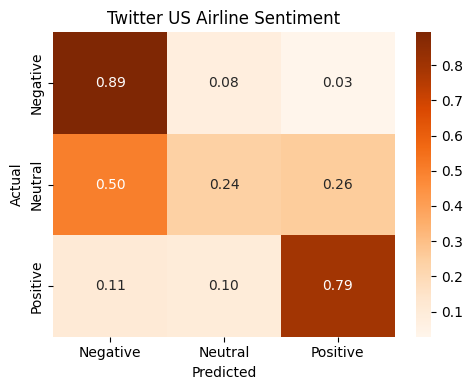


FINAL COMPARISON ACROSS ALL DATASETS
                                Dataset    N  Accuracy %  Macro F1 %  Weighted F1 %
Malaysia Restaurant Reviews (in-domain) 3000       73.47       73.56          73.56
               IMDB Movie Reviews (50K) 3000       72.67       51.01          76.55
                   Yelp Review Polarity 3000       85.70       60.37          90.55
                Amazon Reviews Polarity 3000       79.63       57.42          86.09
     Amazon Reviews Polarity (yacharki) 3000       79.63       57.42          86.09
                 Sentiment140 (Twitter) 3000       58.40       43.52          65.28
           Twitter US Airline Sentiment 3000       73.67       62.33          71.30


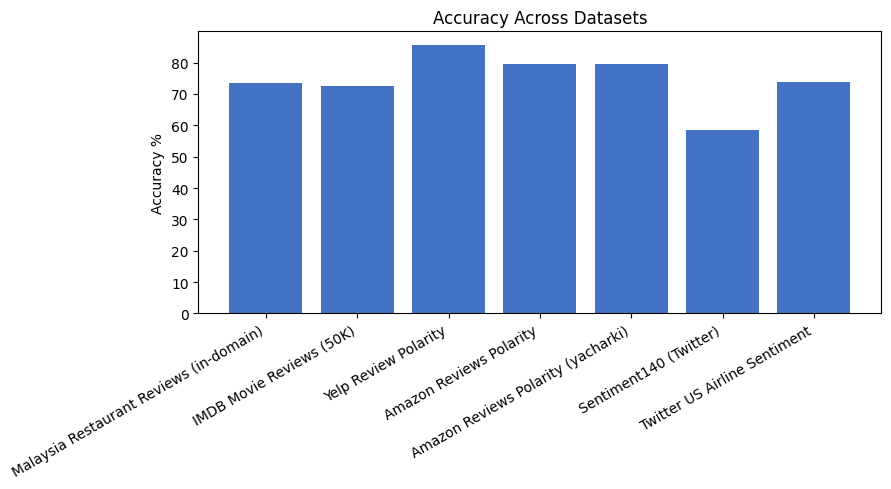

In [5]:
"""
================================================================================
PHASE 5 (ROBUST): TEST ON ANY POPULAR DATASET, EASILY
================================================================================
- Self-contained: won't crash with "label2id not defined" even if run alone.
- Presets for common sentiment datasets - just fill in the Kaggle path.
- Runs a LIST of datasets in one go and prints a final comparison table.

PREREQUISITES: run after Phase 3 + Phase 4 in the same session (needs
best_model, bert_tok, roberta_tok, device, MAX_LEN, predict_texts(),
get_all_predictions(), test_loader). If those aren't in memory, re-run
Phase 3 -> Phase 4 first (both needed for the trained model + tokenizers).
================================================================================
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# --------------------------------------------------------------------------------
# SAFETY NET: define label2id/id2label here too, so this script never breaks
# even if Phase 4 wasn't run right before it in this exact form.
# --------------------------------------------------------------------------------
if "id2label" not in globals():
    id2label = {0: "Negative", 1: "Neutral", 2: "Positive"}
if "label2id" not in globals():
    label2id = {v: k for k, v in id2label.items()}

ALL_LABEL_IDS = sorted(id2label.keys())


# --------------------------------------------------------------------------------
# PRESETS for popular sentiment datasets - column names + label format already
# filled in. You only need to set the Kaggle `path` (check the left panel after
# adding the dataset - "Add Input" - then copy the exact file path).
# --------------------------------------------------------------------------------
PRESETS = {
    "imdb": {
        "name": "IMDB Movie Reviews (50K)",
        "text_col": "review",
        "label_col": "sentiment",
        "mapping": "binary",     # values: positive/negative
        "path_hint": "/kaggle/input/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv",
    },
    "yelp_polarity": {
        "name": "Yelp Review Polarity",
        "text_col": "review_text",
        "label_col": "class_index",
        "mapping": "binary_numeric",   # values: 1=negative, 2=positive
        "path_hint": "/kaggle/input/yelp-reviews-for-sentianalysis-binary-np-csv/test.csv",
    },
    "amazon_polarity": {
        "name": "Amazon Reviews Polarity",
        "text_col": "text",
        "label_col": "polarity",
        "mapping": "binary_numeric",   # values: 1=negative, 2=positive
        "path_hint": "/kaggle/input/amazon-reviews/test.csv",
        "read_kwargs": {"header": None, "names": ["polarity", "title", "text"]},
    },
    "amazon_polarity_v2": {
        "name": "Amazon Reviews Polarity (yacharki)",
        "text_col": "review_text",
        "label_col": "class_index",
        "mapping": "binary_numeric",   # values: 1=negative, 2=positive
        "path_hint": "/kaggle/input/amazon-reviews-for-sa-binary-negative-positive-csv/amazon_review_sa_binary_csv/test.csv",
    },
    "sentiment140": {
        "name": "Sentiment140 (Twitter)",
        "text_col": "text",
        "label_col": "target",
        "mapping": "binary_numeric",   # values: 0=negative, 4=positive
        "path_hint": "/kaggle/input/sentiment140/training.1600000.processed.noemoticon.csv",
        "read_kwargs": {"encoding": "latin-1", "header": None,
                         "names": ["target", "id", "date", "flag", "user", "text"]},
    },
    "twitter_airline": {
        "name": "Twitter US Airline Sentiment",
        "text_col": "text",
        "label_col": "airline_sentiment",
        "mapping": "already_mapped_lower",  # values: positive/neutral/negative (has all 3!)
        "path_hint": "/kaggle/input/twitter-airline-sentiment/Tweets.csv",
    },
    # Note: SST-2 doesn't have one reliable, canonical Kaggle dataset - it's mainly
    # distributed via HuggingFace/GLUE (huggingface.co/datasets/stanfordnlp/sst2).
    # If you want it, download it there and upload as a Kaggle dataset yourself, then
    # add a preset here with mapping="binary_numeric" (label: 0=negative, 1=positive).
}


# --------------------------------------------------------------------------------
# YOUR TEST LIST - add/remove datasets here. `path` MUST be the exact path you
# see on Kaggle after adding the dataset (path_hint is just a common example).
# --------------------------------------------------------------------------------
DATASETS_TO_TEST = [
    {"preset": "imdb",
     "path": "/kaggle/input/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv"},
    {"preset": "yelp_polarity",
     "path": "/kaggle/input/datasets/yacharki/yelp-reviews-for-sentianalysis-binary-np-csv/yelp_review_sa_binary_csv/test.csv"},
    {"preset": "amazon_polarity",
     "path": "/kaggle/input/datasets/kritanjalijain/amazon-reviews/test.csv"},
    {"preset": "amazon_polarity_v2",
     "path": "/kaggle/input/datasets/yacharki/amazon-reviews-for-sa-binary-negative-positive-csv/amazon_review_sa_binary_csv/test.csv"},
    {"preset": "sentiment140",
     "path": "/kaggle/input/datasets/kazanova/sentiment140/training.1600000.processed.noemoticon.csv"},
    {"preset": "twitter_airline",
     "path": "/kaggle/input/datasets/crowdflower/twitter-airline-sentiment/Tweets.csv"},
]


# --------------------------------------------------------------------------------
# MAPPING FUNCTIONS
# --------------------------------------------------------------------------------

def map_stars(rating):
    rating = float(rating)
    if rating >= 4:
        return "Positive"
    elif rating == 3:
        return "Neutral"
    else:
        return "Negative"


BINARY_MAP = {"positive": "Positive", "negative": "Negative", "pos": "Positive", "neg": "Negative"}


def apply_mapping(df, label_col, mapping):
    """Converts any of the popular label formats into {Negative, Neutral, Positive}."""
    if mapping == "stars":
        df["sentiment"] = df[label_col].apply(map_stars)
    elif mapping == "binary":
        df["sentiment"] = df[label_col].astype(str).str.lower().str.strip().map(BINARY_MAP)
    elif mapping == "binary_numeric":
        # covers 0/1, 1/2, 0/4 conventions - anything below the midpoint = Negative
        vals = pd.to_numeric(df[label_col], errors="coerce")
        mid = (vals.min() + vals.max()) / 2
        df["sentiment"] = np.where(vals >= mid, "Positive", "Negative")
    elif mapping == "already_mapped_lower":
        df["sentiment"] = df[label_col].astype(str).str.strip().str.capitalize()
    elif mapping == "already_mapped":
        df["sentiment"] = df[label_col]
    else:
        raise ValueError(f"Unknown mapping type: {mapping}")
    return df


def load_and_map(path, text_col, label_col, mapping, read_kwargs=None):
    df = pd.read_csv(path, **(read_kwargs or {}))
    df = df[[text_col, label_col]].dropna()
    df[text_col] = df[text_col].astype(str).str.strip()
    df = df[df[text_col].str.len() > 0].drop_duplicates(subset=[text_col])
    df = apply_mapping(df, label_col, mapping)
    df["label"] = df["sentiment"].map(label2id)
    df = df.dropna(subset=["label"])
    df["label"] = df["label"].astype(int)
    return df.rename(columns={text_col: "text"})


# --------------------------------------------------------------------------------
# EVALUATE ONE DATASET
# --------------------------------------------------------------------------------

def evaluate_one_dataset(cfg, sample_n=3000, seed=42):
    if "preset" in cfg:
        p = PRESETS[cfg["preset"]]
        name, text_col, label_col, mapping = p["name"], p["text_col"], p["label_col"], p["mapping"]
        read_kwargs = p.get("read_kwargs")
    else:
        name, text_col, label_col, mapping = cfg["name"], cfg["text_col"], cfg["label_col"], cfg["mapping"]
        read_kwargs = cfg.get("read_kwargs")
    path = cfg["path"]

    print(f"\n{'='*70}\nLoading {name}\n{'='*70}")
    try:
        df = load_and_map(path, text_col, label_col, mapping, read_kwargs=read_kwargs)
    except FileNotFoundError:
        print(f"[SKIPPED] File not found at: {path}\n"
              f"-> Add this dataset on Kaggle ('Add Input'), then copy the exact "
              f"path from the left panel into DATASETS_TO_TEST above.")
        return None
    except Exception as e:
        print(f"[SKIPPED] Could not load/map this dataset: {e}")
        return None

    if sample_n and len(df) > sample_n:
        df = df.sample(n=sample_n, random_state=seed).reset_index(drop=True)

    print(f"Loaded {len(df)} usable rows. Class distribution:\n{df['sentiment'].value_counts()}")

    preds, confs = predict_texts(best_model, df["text"].tolist(), bert_tok, roberta_tok, MAX_LEN)
    df["pred"] = preds
    y_true, y_pred = df["label"].values, df["pred"].values

    acc = accuracy_score(y_true, y_pred)
    mf1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    wf1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

    print(f"\nAccuracy: {acc*100:.2f}% | Macro F1: {mf1*100:.2f}% | Weighted F1: {wf1*100:.2f}%")
    print(classification_report(y_true, y_pred, labels=ALL_LABEL_IDS,
                                 target_names=[id2label[i] for i in ALL_LABEL_IDS], zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=ALL_LABEL_IDS, normalize="true")
    cm = np.nan_to_num(cm)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Oranges",
                xticklabels=[id2label[i] for i in ALL_LABEL_IDS],
                yticklabels=[id2label[i] for i in ALL_LABEL_IDS])
    plt.title(f"{name}")
    plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

    return {"dataset": name, "n": len(df), "accuracy": acc, "macro_f1": mf1, "weighted_f1": wf1}


# --------------------------------------------------------------------------------
# RUN ALL DATASETS + FINAL COMPARISON
# --------------------------------------------------------------------------------

def run_all():
    # in-domain reference (your own restaurant-review test set)
    in_pred, in_true, in_probs = get_all_predictions(best_model, test_loader)
    in_acc = accuracy_score(in_true, in_pred)
    in_f1 = f1_score(in_true, in_pred, average="macro", zero_division=0)

    all_results = [{"dataset": "Malaysia Restaurant Reviews (in-domain)", "n": len(in_true),
                     "accuracy": in_acc, "macro_f1": in_f1, "weighted_f1": in_f1}]

    for cfg in DATASETS_TO_TEST:
        result = evaluate_one_dataset(cfg)
        if result:
            all_results.append(result)

    print(f"\n{'='*70}\nFINAL COMPARISON ACROSS ALL DATASETS\n{'='*70}")
    summary = pd.DataFrame(all_results)
    summary["accuracy"] = (summary["accuracy"] * 100).round(2)
    summary["macro_f1"] = (summary["macro_f1"] * 100).round(2)
    summary["weighted_f1"] = (summary["weighted_f1"] * 100).round(2)
    summary = summary.rename(columns={"accuracy": "Accuracy %", "macro_f1": "Macro F1 %",
                                       "weighted_f1": "Weighted F1 %", "dataset": "Dataset", "n": "N"})
    print(summary.to_string(index=False))

    plt.figure(figsize=(9, 5))
    plt.bar(summary["Dataset"], summary["Accuracy %"], color="#4472C4")
    plt.xticks(rotation=30, ha="right")
    plt.ylabel("Accuracy %")
    plt.title("Accuracy Across Datasets")
    plt.tight_layout()
    plt.show()

    return summary


if __name__ == "__main__":
    run_all()